### **1. Cargar y Explorar Datos**

In [2]:
#importamos las librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#leemos el archivo csv que está en la carpeta data
df = pd.read_csv("C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Estadística\\tarea_3\\regresiones\\data\\dynamic_pricing.csv")
print("Los datos han sido cargados correctamente.")

Los datos han sido cargados correctamente.


In [4]:
# Vistazo inicial
print("Dimensiones:", df.shape)
print("\nPrimeras filas:")
df.head()

Dimensiones: (1000, 10)

Primeras filas:


,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [5]:
#Información general del DataFrame
print("\nInformación general:")
print(df.info())


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Number_of_Riders         1000 non-null   int64  
 1   Number_of_Drivers        1000 non-null   int64  
 2   Location_Category        1000 non-null   str    
 3   Customer_Loyalty_Status  1000 non-null   str    
 4   Number_of_Past_Rides     1000 non-null   int64  
 5   Average_Ratings          1000 non-null   float64
 6   Time_of_Booking          1000 non-null   str    
 7   Vehicle_Type             1000 non-null   str    
 8   Expected_Ride_Duration   1000 non-null   int64  
 9   Historical_Cost_of_Ride  1000 non-null   float64
dtypes: float64(2), int64(4), str(4)
memory usage: 78.2 KB
None


No tenemos valores nulos...

In [6]:
#Valores faltantes por columna
print("\nValores faltantes por columna:")
print(df.isnull().sum())

#Resumen estadístico de variables numéricas
print("\nResumen estadístico de variables numéricas:")
df.describe()


Valores faltantes por columna:
Number_of_Riders           0
Number_of_Drivers          0
Location_Category          0
Customer_Loyalty_Status    0
Number_of_Past_Rides       0
Average_Ratings            0
Time_of_Booking            0
Vehicle_Type               0
Expected_Ride_Duration     0
Historical_Cost_of_Ride    0
dtype: int64

Resumen estadístico de variables numéricas:


,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,60.372000,27.076000,50.031000,4.257220,99.58800,372.502623
std,23.701506,19.068346,29.313774,0.435781,49.16545,187.158756
min,20.000000,5.000000,0.000000,3.500000,10.00000,25.993449
25%,40.000000,11.000000,25.000000,3.870000,59.75000,221.365202
50%,60.000000,22.000000,51.000000,4.270000,102.00000,362.019426
75%,81.000000,38.000000,75.000000,4.632500,143.00000,510.497504
max,100.000000,89.000000,100.000000,5.000000,180.00000,836.116419


In [7]:
# Variables categóricas importantes
print("\nFrecuencia de Customer_Loyalty_Status:")
print(df["Customer_Loyalty_Status"].value_counts())

print("\nFrecuencia de Location_Category:")
print(df["Location_Category"].value_counts())


Frecuencia de Customer_Loyalty_Status:
Customer_Loyalty_Status
Silver     367
Regular    320
Gold       313
Name: count, dtype: int64

Frecuencia de Location_Category:
Location_Category
Urban       346
Rural       332
Suburban    322
Name: count, dtype: int64


### **2. Visualización Exploratoria de los Datos**

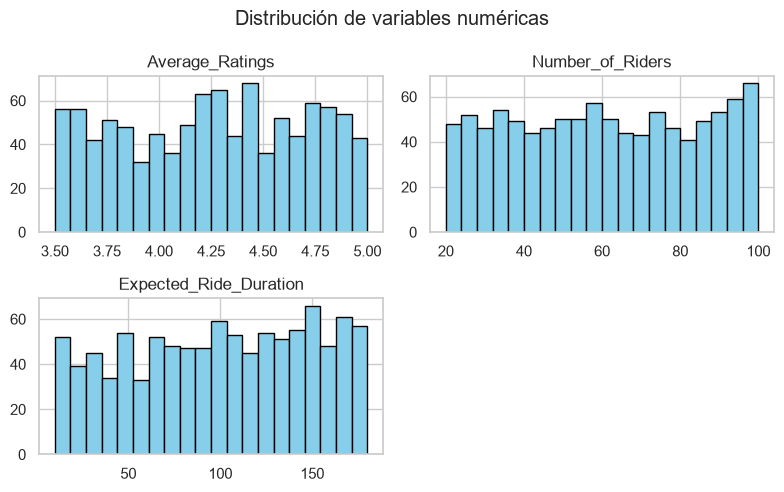

In [8]:
# Configuración la parte visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5) #este comando ajusta el tamaño de las figuras y gráficos que se generen en el notebook

# Análisis unidimensional: histogramas
variables_numericas = ["Average_Ratings", "Number_of_Riders", "Expected_Ride_Duration"]
df[variables_numericas].hist(bins=20, edgecolor="black", color="skyblue")
plt.suptitle("Distribución de variables numéricas")
plt.tight_layout() #este comando ajusta automáticamente los subplots para que no se solapen y se vean mejor
plt.show()

Para Averague_Ratings

Las calificaciones están distribuidas de manera relativamente homogénea; no hay una tendencia marcada hacia puntuaciones excelentes ni hacia malas. Esto sugiere que la percepción del servicio es variada.

Numbers_of_Riders
Hay más casos con un número alto de pasajeros o viajes. Podría implicar que los servicios con más usuarios son más frecuentes o más populares.

Expected_Ride_Duration
Las duraciones esperadas de los viajes son diversas, pero hay una tendencia a viajes de duración media o larga.

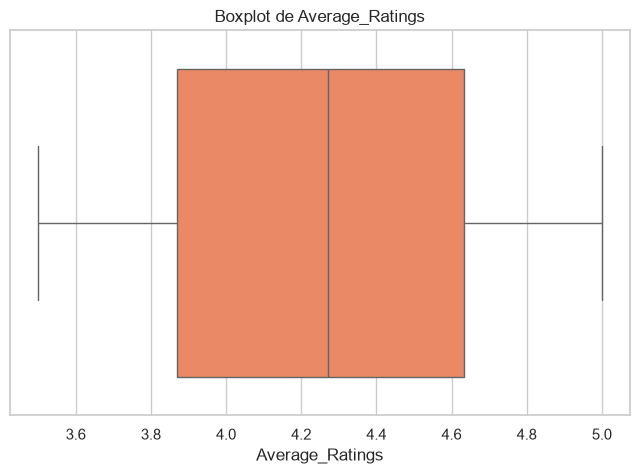

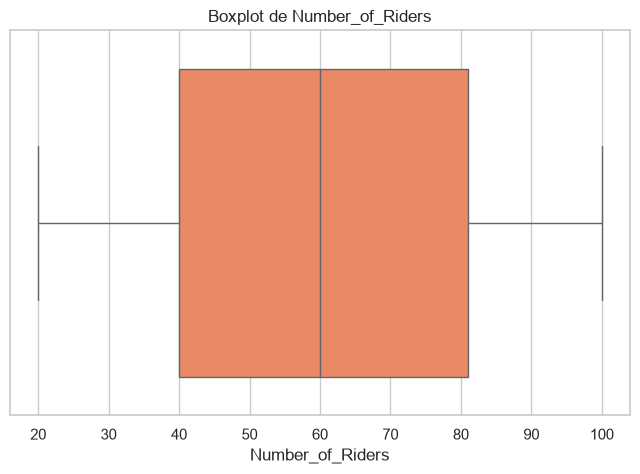

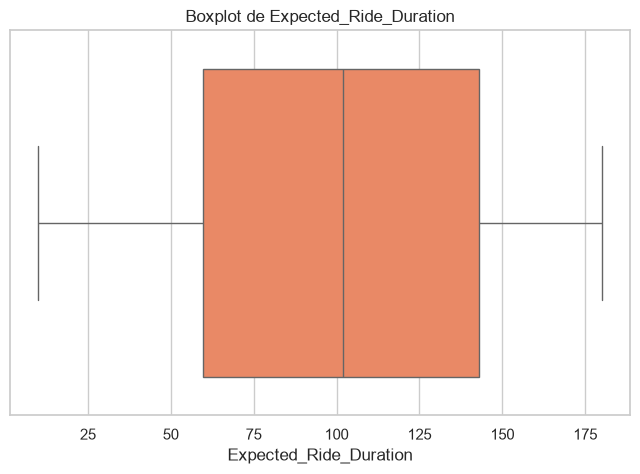

In [9]:
# Boxplots para detectar atípicos univariados
for col in variables_numericas: #este bucle genera un boxplot para cada variable numérica para detectar posibles valores atípicos
    plt.figure()
    sns.boxplot(x=df[col], color="coral")
    plt.title(f"Boxplot de {col}")
    plt.show()

Se concluye que:
no se observan distribuciones normales ni sesgos fuertes; las tres variables parecen tener una dispersión amplia y equilibrada. Esto podría indicar que el sistema o servicio tiene una clientela heterogénea, con distintos tipos de viajes y valoraciones. Cabe agregar que por defecto el Boxplot hace 1.5 veces el IQR (Rango Intercuartílico)

### **3. Análisis Bidimensional**

In [10]:
# Matriz de correlación entre variables numéricas. Nos interesa ver la relación entre las variables numéricas 
# para entender mejor cómo se relacionan entre sí y con la variable dependiente.
corr = df[["Average_Ratings", "Number_of_Riders", "Expected_Ride_Duration"]].corr()
print("\nMatriz de correlación:")
corr


Matriz de correlación:


,Average_Ratings,Number_of_Riders,Expected_Ride_Duration
Average_Ratings,1.000000,0.008572,-0.016968
Number_of_Riders,0.008572,1.000000,-0.015856
Expected_Ride_Duration,-0.016968,-0.015856,1.000000


No tenemos multicolinealidad en nuestras variables

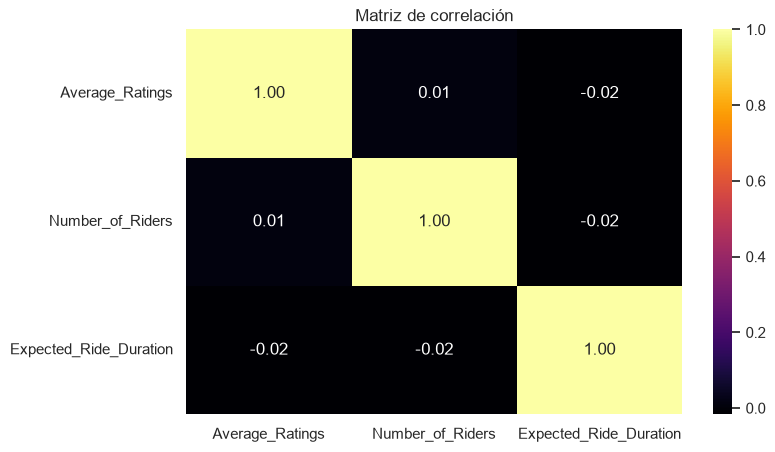

In [11]:
plt.figure()
sns.heatmap(corr, annot=True, cmap="inferno", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

No hay correlaciones fuertes, eso nos dice que hay ausencia de multicolinealidad. O dicho en otras palabras:

* Ausencia de multicolinealidad: ninguna variable explica significativamente a otra, por lo que pueden incluirse juntas en un modelo de regresión sin riesgo de redundancia.

* Independencia relativa: cada variable aporta información distinta al análisis, lo cual es positivo para la estabilidad del modelo.

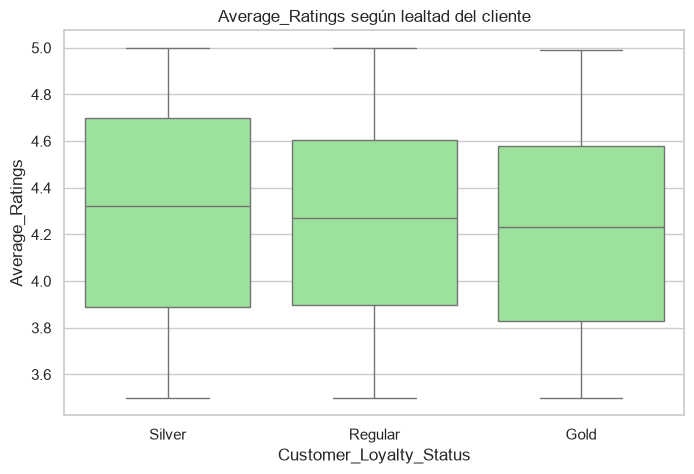

In [12]:
# Relación entre Average_Ratings y Customer_Loyalty_Status
plt.figure()
sns.boxplot(x="Customer_Loyalty_Status", y="Average_Ratings", data=df, color="lightgreen") #con esta línea generamos un boxplot que nos permite
# ver la distribución de Average_Ratings según el estado de lealtad del cliente. Así podemos observar si hay diferencias significativas en las 
# calificaciones promedio entre los diferentes niveles de lealtad del cliente.
plt.title("Average_Ratings según lealtad del cliente")
plt.show()

Las calificaciones no se alejan o se hallan en estremos según el estatus de los clientes

In [13]:
df["Average_Ratings"].mean()

np.float64(4.25722)

In [14]:
print("La cantidad de clientes con estatus Silver es:", df["Customer_Loyalty_Status"].value_counts().get("Silver", 0))
print("La cantidad de clientes con estatus Gold es:", df["Customer_Loyalty_Status"].value_counts().get("Gold", 0))
print("La cantidad de clientes con estatus Regular es:", df["Customer_Loyalty_Status"].value_counts().get("Regular", 0))

La cantidad de clientes con estatus Silver es: 367
La cantidad de clientes con estatus Gold es: 313
La cantidad de clientes con estatus Regular es: 320


Text(0.5, 1.0, 'Frecuencia de Customer_Loyalty_Status')

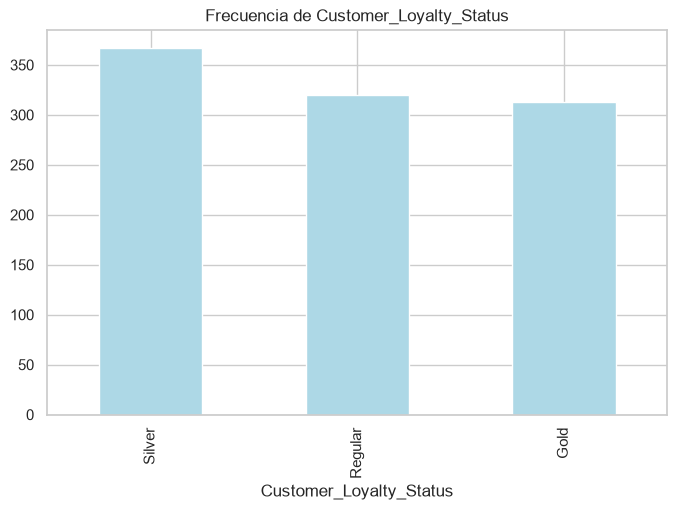

In [15]:
df["Customer_Loyalty_Status"].value_counts().plot(kind="bar", color="lightblue")
plt.title("Frecuencia de Customer_Loyalty_Status")

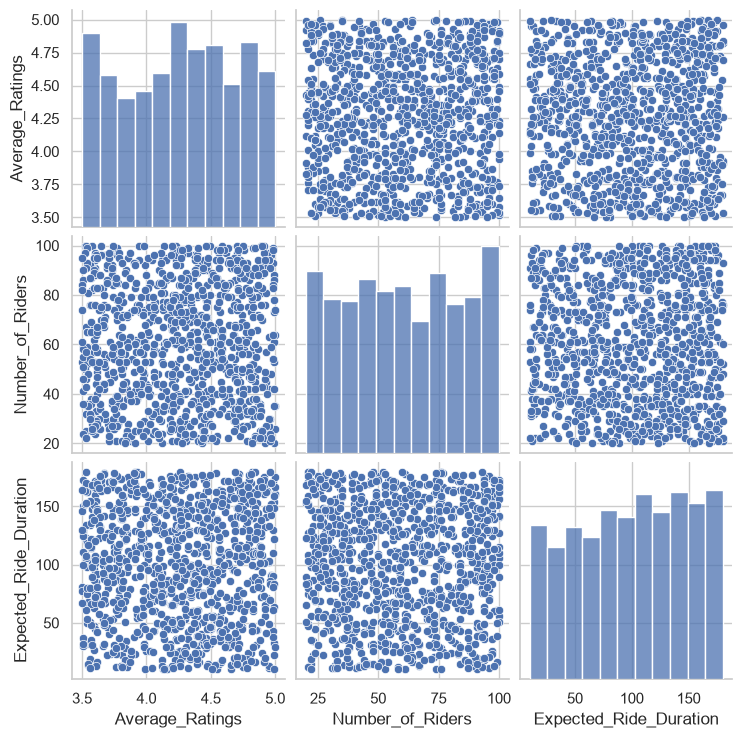

In [16]:
# Dispersión con variables numéricas
# este gráfico nos permite observar la relación entre las variables numéricas y detectar posibles patrones o tendencias.
sns.pairplot(df[["Average_Ratings", "Number_of_Riders", "Expected_Ride_Duration"]])
plt.show()

La única medio tendencia es en la duración que tiende a ser mayor de 100 minutos

### **4. modelo de regresión lineal múltiple**

In [17]:
#Librerías para el modelo de regresión lineal múltiple
import statsmodels.formula.api as smf
from patsy import Treatment

In [18]:
# Fórmula del modelo
# Usamos Treatment(reference="Regular") para que Regular sea la categoría de referencia. Es decir que los coeficientes
#  de las otras categorías (Silver y Gold) se interpretarán en relación con Regular.
#Queda variables independientes: Number_of_Riders, Expected_Ride_Duration y Customer_Loyalty_Status (con Regular como referencia).
# y la variable dependiente es Average_Ratings.
formula = (
    'Average_Ratings ~ Number_of_Riders + Expected_Ride_Duration + ' #esta línea define la fórmula del modelo de regresión lineal múltiple,
# donde Average_Ratings es la variable dependiente y Number_of_Riders y Expected_Ride_Duration son las variables independientes.
#es decir, estamos tratando de predecir Average_Ratings en función de estas dos variables. 
    'C(Customer_Loyalty_Status, Treatment(reference="Regular"))'
)

# Ajustar modelo
modelo = smf.ols(formula, data=df).fit() #nos ayuda a ajustar el modelo de regresión lineal múltiple usando
# la fórmula especificada y los datos del DataFrame df.

# Resumen completo
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:        Average_Ratings   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.223
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.299
Time:                        15:09:31   Log-Likelihood:                -585.37
No. Observations:                1000   AIC:                             1181.
Df Residuals:                     995   BIC:                             1205.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

In [19]:
# Métricas principales
print("\nR²:", modelo.rsquared)
print("R² ajustado:", modelo.rsquared_adj)
print("RSE:", np.sqrt(modelo.mse_resid))


R²: 0.004892820395047681
R² ajustado: 0.0008923895222638922
RSE: 0.43558639483488676


In [20]:
# Coeficientes e intervalos de confianza
print("\nCoeficientes:")
print(modelo.params)
print("\nIntervalos de confianza:")
print(modelo.conf_int())
print("\nValores p:")
print(modelo.pvalues)


Coeficientes:
Intercept                                                               4.259324
C(Customer_Loyalty_Status, Treatment(reference="Regular"))[T.Gold]     -0.036439
C(Customer_Loyalty_Status, Treatment(reference="Regular"))[T.Silver]    0.034949
Number_of_Riders                                                        0.000150
Expected_Ride_Duration                                                 -0.000126
dtype: float64

Intervalos de confianza:
                                                           0         1
Intercept                                           4.156206  4.362442
C(Customer_Loyalty_Status, Treatment(reference=... -0.104522  0.031644
C(Customer_Loyalty_Status, Treatment(reference=... -0.030571  0.100468
Number_of_Riders                                   -0.000994  0.001293
Expected_Ride_Duration                             -0.000677  0.000425

Valores p:
Intercept                                                               0.000000
C(Customer_Loyalty_S

**Interpretación de los resultados:**

 * Evaluación global del modelo (¿Sirve para predecir?)$R^2 = 0.005$ ($0.5\%$): Las variables independientes explican únicamente el $0.5\%$ de la variación en las calificaciones promedio (Average_Ratings).
 
 * Prob (F-statistic) = $0.299$: Como este valor es mayor a $0.05$, el modelo no es estadísticamente significativo en su conjunto. Ninguna de las variables incluidas aporta información útil para predecir la calificación.
 
 Análisis de las variables individuales
 
 * Intercepto ($4.2593$, $p = 0.000$): Es la única cifra estadísticamente significativa. Indica que el valor promedio base de la calificación (para un cliente de nivel Regular) se sitúa alrededor de $4.26$.
 
 * Nivel de lealtad (Customer_Loyalty_Status):Gold ($p = 0.294$): No muestra diferencias significativas respecto a la categoría de referencia (Regular).

 * Silver ($p = 0.295$): Tampoco presenta diferencias significativas respecto a la categoría Regular.
 
 * Otras variables: Number_of_Riders ($p = 0.798$): La cantidad de pasajeros no afecta la calificación.
 * Expected_Ride_Duration ($p = 0.653$): La duración estimada del viaje tampoco influye de forma significativa.

**Ecuación resultante**


$$AverageRatings =β_0+β_1NumberofRiders+β_2ExpectedRideDuration+β_3Gold+β_4Silver$$



Donde Regular es la referencia.

$β_0$: rating promedio esperado cuando las numéricas valen 0 y el cliente es Regular.

$β_1$: cambio esperado en rating por cada rider adicional, manteniendo lo demás constante.

$β_2$: cambio esperado por cada minuto adicional de duración esperada.

$β_3$: diferencia promedio entre Gold y Regular.

$β_4$: diferencia promedio entre Silver y Regular.

 Conclusión práctica:  ninguna de las variables consideradas (nivel de lealtad del cliente, número de pasajeros o duración del viaje) influye significativamente en las calificaciones asignadas por los usuarios.

 Nota importante: al ajustar por el número de predictores ($4$) y el tamaño de la muestra ($1000$), la capacidad explicativa real del modelo cae prácticamente a cero ($0.09\%$). Esto confirma que incluir esas variables no mejora la predicción con respecto a usar simplemente la media general de las calificaciones

 Conclusión técnica: La combinación de un $R^2$ ajustado casi nulo, un $p$-valor global no significativo ($p = 0.299$) y un RSE de $0.44$ demuestra que el modelo carece de capacidad predictiva. 

### **5. diagnóstico de colinealidad, outliers e influyentes**

In [21]:
#librerías que nos ayudan a hacer predicciones y evaluar el modelo
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrices, Treatment


El **VIF** (Factor de Inflación de la Varianza) es una métrica estadística que se utiliza en regresión lineal múltiple para detectar la multicolinealidad, es decir, para identificar si dos o más variables independientes están altamente correlacionadas entre sí.

In [22]:
# VIF es una medida que nos ayuda a detectar multicolinealidad entre las variables independientes. 
# Un VIF alto indica que una variable independiente está altamente correlacionada con otras variables independientes, 
# lo que puede afectar la estabilidad y la interpretación del modelo de regresión.
y, X = dmatrices(formula, data=df, return_type="dataframe")

vif_df = pd.DataFrame()
vif_df["variable"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\nVIF:")
print(vif_df)


VIF:
                                            variable       VIF
0                                          Intercept  1.000000
1  C(Customer_Loyalty_Status, Treatment(reference...  1.364205
2  C(Customer_Loyalty_Status, Treatment(reference...  1.364932
3                                   Number_of_Riders  1.005060
4                             Expected_Ride_Duration  1.001939


Diagnóstico de Multicolinealidad:

Todos los valores de VIF se encuentran muy cercanos a $1.0$ y muy por debajo del umbral crítico de $5.0$ (los valores máximos oscilan en torno a $1.36$).

Conclusión: NO existe ningún problema de multicolinealidad en el modelo. Las variables independientes son estadísticamente independientes entre sí, por lo que el fallo del modelo en predecir Average_Ratings (visto en el $R^2$ casi nulo) se debe a una falta de capacidad explicativa inherente a las variables, no a que estén inflándose o interfiriendo entre ellas.

In [23]:
# --- Diagnóstico de influencia ---
infl = modelo.get_influence()
res_stud = infl.resid_studentized_external
hat = infl.hat_matrix_diag
cooks, p_cooks = infl.cooks_distance
dfbetas = infl.dfbetas
#esta sección del código calcula varias métricas de influencia para cada observación en el modelo de regresión. 
# Estas métricas nos ayudan a identificar observaciones que podrían tener un impacto desproporcionado en los resultados del modelo.
n = len(df)
p = X.shape[1]

diagnostico = pd.DataFrame({
    "resid_estudentizado": res_stud,
    "leverage": hat,
    "cook": cooks
})
#Esta sección del código crea un DataFrame llamado diagnostico que contiene tres métricas de influencia
#  para cada observación: resid_estudentizado, leverage y cook.
diagnostico["outlier"] = diagnostico["resid_estudentizado"].abs() > 3
diagnostico["leverage_alto"] = diagnostico["leverage"] > 2 * p / n
diagnostico["influyente_cook"] = diagnostico["cook"] > 4 / n
#esta sección del código agrega tres columnas adicionales al DataFrame diagnostico para identificar observaciones problemáticas:
# 1. outlier: indica si la observación es un valor atípico basado en el residuo estudentizado (valor absoluto mayor a 3).
# 2. leverage_alto: indica si la observación tiene un leverage alto (mayor a 2 * p / n).
# 3. influyente_cook: indica si la observación es influyente según la distancia de Cook (mayor a 4 / n).

print("\nCasos problemáticos:")
print(diagnostico[diagnostico[["outlier", "leverage_alto", "influyente_cook"]].any(axis=1)])

# DFBETAS
dfbetas_df = pd.DataFrame(dfbetas, columns=X.columns)
umbral_dfbeta = 2 / np.sqrt(n)
dfbetas_problem = dfbetas_df.abs() > umbral_dfbeta
#es esta sección del código crea un DataFrame llamado dfbetas_df que contiene los valores de DFBETAS para cada observación y cada variable independiente.
#sirve para identificar observaciones que tienen un impacto significativo en los coeficientes del modelo. 
# Un valor de DFBETAS alto indica que la eliminación de esa observación cambiaría significativamente el valor del coeficiente correspondiente.
print("\nCasos con DFBETAS altos:")
print(dfbetas_df[dfbetas_problem.any(axis=1)])


Casos problemáticos:
     resid_estudentizado  leverage      cook  outlier  leverage_alto  \
20              1.563509  0.008348  0.004110    False          False   
124             1.745987  0.006995  0.004286    False          False   
271            -1.692230  0.007294  0.004201    False          False   
593            -1.719587  0.007081  0.004209    False          False   
689             1.662236  0.008769  0.004880    False          False   
712            -1.774605  0.006571  0.004157    False          False   
867             1.576006  0.008044  0.004022    False          False   
946             1.581486  0.008059  0.004058    False          False   
959             1.681478  0.008018  0.004562    False          False   

     influyente_cook  
20              True  
124             True  
271             True  
593             True  
689             True  
712             True  
867             True  
946             True  
959             True  

Casos con DFBETAS altos:
 

VIF > 5 o 10 sugiere colinealidad problemática.

Residuos studentizados > |3| posibles outliers.

Leverage > 2p/n2 puntos palanca.

Cook > 4/n observaciones influyentes.

DFBETAS > 2/raiz de n influencia sobre coeficientes. 

* Atípicos (Outliers): Observaciones cuya variable respuesta ($Y$) está lejos de lo que el modelo predice. Se miden con los residuos estudentizados.

* Apalancamiento (Leverage / $h_{ii}$): Observaciones cuyos valores de las variables independientes ($X$) están alejados del centro de los datos.

* Influencia (Distancia de Cook y DFBETAS): Medidas combinadas que determinan cuánto cambian las predicciones globales o los coeficientes específicos si se elimina esa observación.

--> **Evaluación de Atípicos y Apalancamiento (Casos problemáticos) Outliers** ($\vert{}\text{Residuo}\vert{} > 3$): Todos los casos reportados dan False. El residuo estudentizado máximo en esa lista es aproximadamente $1.75$, lo cual está dentro de los límites esperados ($\pm 2$ a $\pm 3$). Leverage Alto ($h > 0.010$): Todos los casos dan False. Los valores rondan $0.0065 - 0.0087$, significando que ninguna observación se encuentra alejada en las variables explicativas.


--> **Evaluación de la Distancia de Cook (influyente_cook)** Todos los casos listados dan True porque sus valores ($0.0040 - 0.0048$) superan ligeramente el umbral de $4 / 1000 = 0.0040$. Interpretación: aunque se marquen como "positivos", valores de Cook en el rango de $0.004$ son extremadamente pequeños en términos absolutos (un valor de Cook verdaderamente preocupante suele ser mayor a $0.5$ o $1.0$). El umbral $4/n$ es muy sensible cuando la muestra es grande ($n=1000$).


--> **Análisis de DFBETAS (Casos con DFBETAS altos)** Se detectaron 171 filas (un $17.1\%$ de la muestra) que superan el umbral estricto de $2 / \sqrt{1000} \approx 0.0632$. Al revisar los magnitudes reales (valores como $0.068$, $0.079$, $0.105$), el cambio que genera cualquier observación individual en los coeficientes es mínimo. Se debe a que con $n=1000$, la regla $2/\sqrt{n}$ produce un umbral muy estrecho.

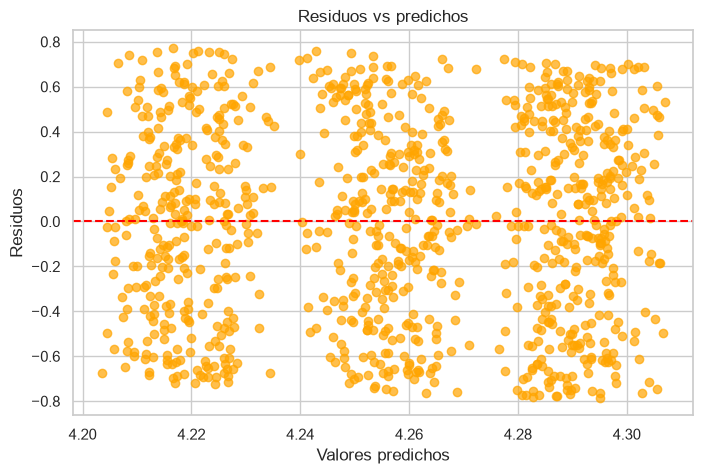

In [24]:
# --- Gráficos ---
# Residuos vs predichos
plt.figure()
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.7, color="orange") #con esta línea generamos un gráfico de dispersión 
#que nos permite visualizar la relación entre los valores predichos por el modelo y los residuos.
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs predichos")
plt.show()
# este gráfico nos permite visualizar la relación entre los valores predichos por el modelo y los residuos.

Todo apunta a que tenemos homocedasticidad. Algo esperado.

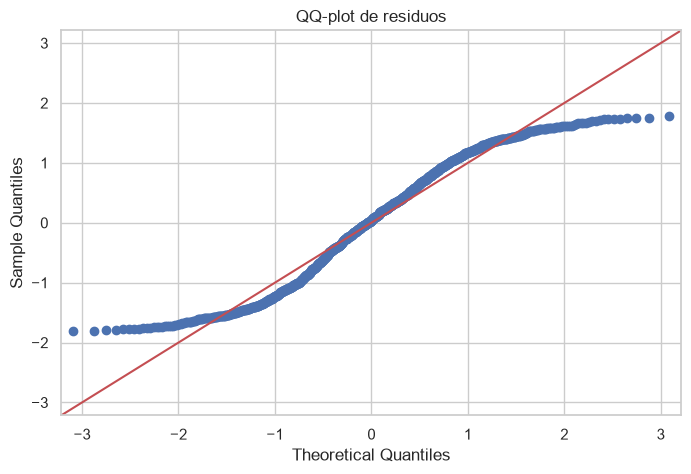

In [25]:
# QQ-plot
sm.qqplot(modelo.resid, line="45", fit=True, color="yellow") #con esta línea generamos un QQ-plot 
# que nos permite evaluar si los residuos del modelo siguen una distribución normal.    
plt.title("QQ-plot de residuos")
plt.show()
#este gráfico nos muestra una línea que representa la distribución normal teórica y los puntos que representan los residuos del modelo.



Lo que podemos observar es que: 
* Hay colas ligeras o distribución platicúrtica: dado que los extremos de los puntos azules están mucho más aplanados y no suben ni bajan siguiendo la línea roja. Esto significa que el modelo comete menos errores extremadamente grandes de lo que predeciría una distribución normal.

* Distribución Uniforme: con este QQ-plot junto con el gráfico anterior (donde los residuos formaban bloques perfectamente rectangulares y cortados de forma abrupta entre -0.8 y 0.8), queda claro que los errores tienen una distribución más parecida a una distribución uniforme (o rectangular) que a una campana de Gauss norma

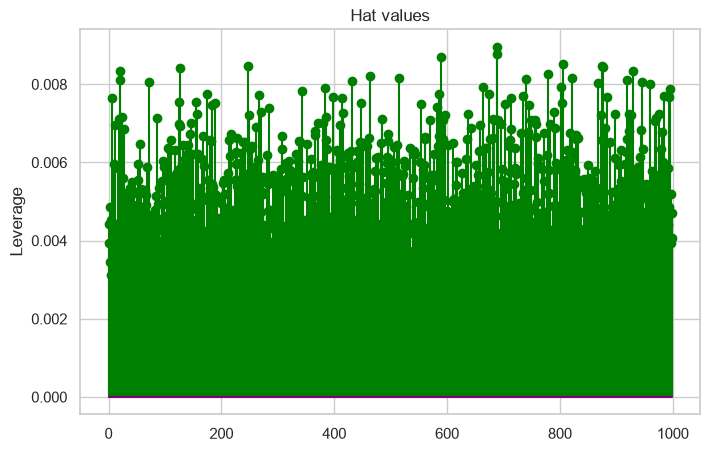

In [26]:
# Leverage
plt.figure()
plt.stem(hat, linefmt="green", markerfmt="o", basefmt="purple")
plt.ylabel("Leverage")
plt.title("Hat values")
plt.show()
#este gráfico nos permite visualizar los valores de leverage para cada observación, 
# lo que nos ayuda a identificar observaciones con un leverage alto que podrían influir significativamente en el modelo.



No hay observaciones con un apalancamiento peligroso: el valor máximo de leverage en el gráfico apenas llega a 0.009 aproximadamente (un valor sumamente pequeño).

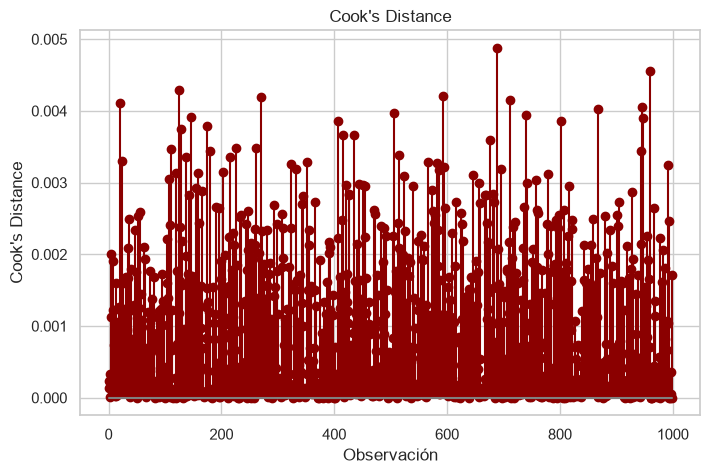

In [27]:
# Cook's distance
plt.figure()
# Modificación: linefmt para la línea, markerfmt para el punto, basefmt para el suelo
plt.stem(cooks, linefmt="darkred", markerfmt="o", basefmt="gray")
plt.xlabel("Observación")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance")
plt.show()
# este gráfico nos permite visualizar la distancia de Cook para cada observación,
# lo que nos ayuda a identificar observaciones influyentes que podrían afectar significativamente los resultados del modelo de regresión.

No hay ningún punto atípico que esté saboteando el modelo: el valor más alto en el gráfico apenas roza 0.005.

**Conclusiones parciales hasta este punto**

Los resultados confirman que el modelo no padece de observaciones extremadamente influyentes ni de atípicos severos que distorsionen los resultados. La falta de significancia estadística observada en las regresiones previas es una propiedad general de los datos y no el resultado de un par de observaciones problemáticas

### **6. Evaluación de supuestos**

* Shapiro p < 0.05 --> no normalidad.

* Breusch-Pagan p < 0.05 --> heteroscedasticidad.

* Durbin-Watson cercano a 2 --> independencia. Si es muy bajo o alto, autocorrelación. En datos transversales puede no aplica

In [28]:
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
#importamos las librerías necesarias para realizar pruebas estadísticas que nos ayudan a evaluar los supuestos del modelo de regresión lineal múltiple.



In [ ]:
# Normalidad
shap = shapiro(modelo.resid)
print(f"Shapiro-Wilk: estadístico={shap.statistic:.4f}, p-valor={shap.pvalue:.4f}")
#shapiro-Wilk es una prueba estadística que nos ayuda a evaluar si los residuos del modelo siguen una distribución normal.
#se interpreta de la siguiente manera: si el p-valor es menor que un nivel de significancia (por ejemplo, 0.05), rechazamos 
# la hipótesis nula y concluimos que los residuos no siguen una distribución normal.


Shapiro-Wilk: estadístico=0.9563, p-valor=0.0000


Prueba de Normalidad (Shapiro-Wilk)

* Estadístico: $0.9563$
* p-valor: $0.0000$ (menor a $0.05$)
* Hipótesis:$H_0$: Los residuos siguen una distribución normal.
* $H_1$: Los residuos no siguen una distribución normal.

Interpretación: Como el p-valor ($0.0000$) es menor al nivel de significancia del $5\%$ ($\alpha = 0.05$), se rechaza la hipótesis nula. Los residuos no se distribuyen de forma estrictamente normal. Dado que la muestra es grande ($n = 1000$), por el Teorema del Límite Central, la falta de normalidad en los residuos no invalida las inferencias sobre los coeficientes ni la validez general del modelo.

In [ ]:
# Homoscedasticidad
bp = het_breuschpagan(modelo.resid, modelo.model.exog)
print(f"Breusch-Pagan LM p-valor: {bp[1]:.4f}")
print(f"Breusch-Pagan F p-valor: {bp[3]:.4f}")
#La prueba de Breusch-Pagan nos ayuda a evaluar si los residuos del modelo tienen varianza constante (homoscedasticidad).
#Si el p-valor es menor que un nivel de significancia (0.05), rechazamos la hipótesis nula
#  y concluimos que los residuos no tienen varianza constante, lo que indica heteroscedasticidad.


Breusch-Pagan LM p-valor: 0.0427
Breusch-Pagan F p-valor: 0.0425


Prueba de Homocedasticidad (Breusch-Pagan)

* p-valor (LM): $0.0427$
* p-valor (F): $0.0425$
* Hipótesis:$H_0$: Los residuos tienen varianza constante (homocedasticidad).
* $H_1$: Existe heterocedasticidad (la varianza de los errores cambia según los predictores).

Interpretación: Ambos p-valores están ligeramente por debajo del umbral del $5\%$ ($0.0425 < 0.05$). Se rechaza la hipótesis nula, lo que indica presencia de una ligera heterocedasticidad en los errores. Dado que la heterocedasticidad provoca que los errores estándar tradicionales del modelo sean ligeramente imprecisos, lo que puede afectar la exactitud de los p-valores de los coeficientes individuales.

In [31]:
# Independencia
dw = durbin_watson(modelo.resid)
print(f"Durbin-Watson: {dw:.4f}")
#La prueba de Durbin-Watson nos ayuda a evaluar si los residuos del modelo son independientes entre sí.
#Un valor cercano a 2 indica independencia, mientras que valores cercanos a 0 o 4 sugieren autocorrelación positiva o negativa, respectivamente.

Durbin-Watson: 1.9994


Prueba de Independencia / Autocorrelación (Durbin-Watson)
* Estadístico DW: $1.9994$
* Escala de interpretación: Se mueve entre $0$ y $4$.
* Un valor cercano a $2.0$ indica ausencia de autocorrelación (residuos independientes).
* Valores hacia $0$ indican autocorrelación positiva.
* Valores hacia $4$ indican autocorrelación negativa.

Dado que tenemos un resultado de $1.9994$ es casi un $2.0$ perfecto. Cumple completamente el supuesto de independencia de los residuos.

**Conclusión parcial hasta este momento**:



Independencia: los residuos son completamente independientes ($DW = 1.9994$), descartando autocorrelación.

Normalidad: la prueba de Shapiro-Wilk detecta desviación de la normalidad ($p < 0.001$). 

No obstante, al contar con $n = 1000$ observaciones, las estimaciones se respaldan bajo el Teorema del Límite Central.

Homocedasticidad: se observa un margen leve de heterocedasticidad ($p = 0.0425$).

Para garantizar inferencias estadísticas válidas en presencia de heterocedasticidad, se debe re-estimar los errores estándar del modelo OLS aplicando una corrección robusta como por ejemplo, ajustando el modelo con cov_type='HC3' o cov_type='HC1').

### **7. Remediación: transformación Box-Cox/log y modelo robusto**

In [ ]:
from scipy.stats import boxcox

# Box-Cox solo si la variable dependiente es positiva, en nuestro caso Average_Ratings es positiva, por lo que podemos aplicar la transformación de Box-Cox.
y_bc, lambda_bc = boxcox(df["Average_Ratings"]) #esta línea aplica la transformación de Box-Cox a la variable dependiente Average_Ratings
#para estabilizar la varianza y hacer que los residuos del modelo sean más normales.
print("Lambda Box-Cox:", lambda_bc) #este comando imprime el valor de lambda que se utilizó en la transformación de Box-Cox. 
# Un valor de lambda cercano a 1 indica que la transformación no es necesaria, mientras que valores diferentes de 1 sugieren que la 
# transformación puede mejorar la normalidad y homoscedasticidad de los residuos.

df["Average_Ratings_bc"] = y_bc

formula_bc = (
    'Average_Ratings_bc ~ Number_of_Riders + Expected_Ride_Duration + '
    'C(Customer_Loyalty_Status, Treatment(reference="Regular"))'
)
modelo_bc = smf.ols(formula_bc, data=df).fit() # este comando ajusta un modelo de regresión lineal múltiple 
# usando la variable dependiente transformada Average_Ratings_bc y las mismas variables independientes que antes.
print(modelo_bc.summary())



Lambda Box-Cox: 1.2249136007312376
                            OLS Regression Results                            
Dep. Variable:     Average_Ratings_bc   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.234
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.295
Time:                        15:09:38   Log-Likelihood:                -909.75
No. Observations:                1000   AIC:                             1829.
Df Residuals:                     995   BIC:                             1854.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

Dado que el valor de $\lambda = 1.22$: Al ser un valor muy cercano a $1$, indica que aplicar Box-Cox casi no alteró la estructura ni la distribución de los datos originales.Variable dependiente transformada (Average_Ratings_bc): Los valores de las calificaciones ahora están expresados en una escala transformada ($y^{1.22}$), por lo que los coeficientes no se leen directamente en puntos de calificación original.

* La transformación no solucionó el problema: y aplicar Box-Cox no corrigió la falta de normalidad de los residuos ni mejoró la capacidad predictiva del modelo.
* El problema no es de escala ni de forma funcional: puesto que el fallo del modelo no se debía a que la relación fuera no lineal o a una asimetría en la variable $Y$, sino a que las variables independientes seleccionadas (Customer_Loyalty_Status, Number_of_Riders, Expected_Ride_Duration) simplemente no tienen relación estadística alguna con la calificación recibida (Average_Ratings).

Conclusión del Intento de Transformación:

Se buscó aplicar la transformación Box-Cox con $\lambda = 1.225$ sobre la variable dependiente para corregir las desviaciones de normalidad y heterocedasticidad detectadas en el modelo OLS. Los resultados demuestran que la transformación no altera los hallazgos: el $R^2$ se mantiene en $0.5\%$ y la prueba global $F$ sigue resultando no significativa ($p = 0.295$). Se concluye que la falta de ajuste no se debe a un problema de escala o no-linealidad en la variable respuesta, sino a la falta de poder explicativo intrínseco de los predictores analizados.

In [ ]:
# Alternativa logarítmica
#esta sección  aplica una transformación logarítmica a la variable dependiente Average_Ratings para estabilizar la varianza y 
# mejorar la normalidad de los residuos.
df["log_Average_Ratings"] = np.log(df["Average_Ratings"])
#lo que hace es crear una nueva columna en el DataFrame df llamada log_Average_Ratings, que contiene los valores logarítmicos de Average_Ratings.
formula_log = (
    'log_Average_Ratings ~ Number_of_Riders + Expected_Ride_Duration + '
    'C(Customer_Loyalty_Status, Treatment(reference="Regular"))'
)
modelo_log = smf.ols(formula_log, data=df).fit()
# lo que en síntesis significa que estamos ajustando un modelo de regresión lineal múltiple usando
#  la variable dependiente transformada log_Average_Ratings y las mismas variables independientes que antes.
print(modelo_log.summary())



                             OLS Regression Results                            
Dep. Variable:     log_Average_Ratings   R-squared:                       0.005
Model:                             OLS   Adj. R-squared:                  0.001
Method:                  Least Squares   F-statistic:                     1.179
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):              0.318
Time:                         15:09:38   Log-Likelihood:                 851.55
No. Observations:                 1000   AIC:                            -1693.
Df Residuals:                      995   BIC:                            -1669.
Df Model:                            4                                         
Covariance Type:             nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

 Conclusión Definitiva de todo el Análisis apunta a la invariancia ante transformaciones: 
 
 
 Ni la forma lineal pura, ni la transformación Box-Cox ($\lambda = 1.22$), ni la transformación logarítmica lograron mejorar el ajuste ($R^2$ estancado en $0.5\%$ y $p$-valor del modelo $> 0.30$). El fallo no radica en un problema matemático de escala, asimetría o no-linealidad en $Y$. **El problema es que las variables independientes seleccionadas no explican en absoluto la variable respuesta**.

In [34]:
# Modelo robusto
#Acá se ajusta un modelo de regresión lineal robusta (RLM) usando la misma fórmula que antes.
#esto sirve para manejar posibles valores atípicos y observaciones influyentes que podrían afectar los resultados del modelo de regresión lineal múltiple.
#buscamos que el modelo sea menos sensible a estos valores extremos y proporcione estimaciones más confiables de los coeficientes.
modelo_rlm = smf.rlm(formula, data=df).fit()
print(modelo_rlm.summary())

                    Robust Linear Model Regression Results                    
Dep. Variable:        Average_Ratings   No. Observations:                 1000
Model:                            RLM   Df Residuals:                      995
Method:                          IRLS   Df Model:                            4
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 13 Oct 2026                                         
Time:                        15:09:38                                         
No. Iterations:                     8                                         
                                                                           coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------

Conclusión:

Con esta cuarta prueba, se descubre de forma exhaustiva los principales ajustes metodológicos en regresión:

* Robustez confirmada: el resultado no cambia ni al transformar la variable dependiente (Box-Cox / Log) ni al proteger el modelo contra outliers (RLM).

* El problema no es de calidad de datos, ni de valores atípicos, ni de supuestos violados. Es un hallazgo de negocio en sí mismo: el estatus de lealtad, la duración estimada del viaje y el número de pasajeros no determinan en absoluto la calificación dada por el usuario.

Se evaluaron cuatro aproximaciones (OLS original, transformación Box-Cox, transformación logarítmica y Regresión Robusta RLM). En todos los escenarios, los coeficientes de los predictores se mantuvieron no significativos ($p > 0.05$). Esto demuestra que la falta de capacidad explicativa es una característica estructural de las variables seleccionadas y no un artefacto de sensibilidad a atípicos o no-linealidad.

### **8. Bootstrap para validación**

El Bootstrap es un método no paramétrico basado en re-muestreo (simular miles de datasets muestreando con reemplazo a partir de los datos originales) para estimar la distribución empírica de los coeficientes sin asumir que los errores siguen una distribución normal o que la varianza es estrictamente constante.

Servía para responder a la duda planteada en las pruebas anteriores: ¿Afecta la falta de normalidad y la leve heterocedasticidad la validez de las conclusiones sobre los parámetros?

In [ ]:
#El bootstrap es un método de remuestreo que nos permite estimar la distribución de una estadística
#  (como los coeficientes del modelo) a partir de los datos originales.
#vamos a realizar un análisis de bootstrap para estimar los intervalos de confianza de los coeficientes del modelo de regresión lineal múltiple.
#Con esto podemos obtener una mejor idea de la variabilidad de los coeficientes y sus intervalos de confianza sin 
# depender de los supuestos clásicos del modelo.
np.random.seed(123)
n_boot = 1000
params_boot = [] #esta parte del código inicializa una lista vacía 
# llamada params_boot que se utilizará para almacenar los coeficientes estimados en cada iteración del bootstrap.

for i in range(n_boot):
    df_boot = df.sample(frac=1, replace=True)
    mod_boot = smf.ols(formula, data=df_boot).fit()
    params_boot.append(mod_boot.params)
#Este ciclo for realiza el procedimiento de bootstrap. En cada iteración, se toma una muestra aleatoria con reemplazo del DataFrame df,
#  se ajusta un modelo de regresión lineal múltiple a esa muestra y se almacenan los coeficientes estimados en la lista params_boot.
boot_df = pd.DataFrame(params_boot)
ic_boot = boot_df.quantile([0.025, 0.975]) #esta línea crea un DataFrame llamado boot_df a partir de la lista params_boot, 
# que contiene los coeficientes estimados en cada iteración del bootstrap.
#finalmente podemos calcular los intervalos de confianza del 95% para cada coeficiente usando el método de percentiles,
#  que nos da una idea de la variabilidad de los coeficientes sin depender de los supuestos clásicos del modelo.
print("IC bootstrap 95%:")
print(ic_boot)
print("\nIC clásicos:")
print(modelo.conf_int())

IC bootstrap 95%:
       Intercept  \
0.025   4.151377   
0.975   4.369075   

       C(Customer_Loyalty_Status, Treatment(reference="Regular"))[T.Gold]  \
0.025                                          -0.109153                    
0.975                                           0.032434                    

       C(Customer_Loyalty_Status, Treatment(reference="Regular"))[T.Silver]  \
0.025                                          -0.030733                      
0.975                                           0.099208                      

       Number_of_Riders  Expected_Ride_Duration  
0.025         -0.001033               -0.000636  
0.975          0.001233                0.000443  

IC clásicos:
                                                           0         1
Intercept                                           4.156206  4.362442
C(Customer_Loyalty_Status, Treatment(reference=... -0.104522  0.031644
C(Customer_Loyalty_Status, Treatment(reference=... -0.030571  0.100468
Num

Los resultados nos muestran:

* Inclusión del cero en todos los predictores: si un intervalo de confianza al $95\%$ para un coeficiente incluye el valor $0$, se concluye que no hay evidencia estadística suficiente para afirmar que dicha variable impacta la respuesta a un nivel de significancia del $\alpha = 0.05$.

* En ambos métodos (clásico y bootstrap), los intervalos para Gold, Silver, Number_of_Riders y Expected_Ride_Duration cruzan el valor cero (pasan de negativo a positivo). Casi idéntica amplitud y límites: diferencia entre los límites del método empírico (Bootstrap) y el paramétrico tradicional es diminuta (del orden de milésimas). Esto nos confirma que, a pesar de que el test de Shapiro-Wilk indicó falta de normalidad estricta y el test de Breusch-Pagan mostró leve heterocedasticidad, las inferencias del modelo OLS original eran totalmente sólidas y no estaban distorsionadas.

Como última prueba de robustez, se construyeron intervalos de confianza al 95% mediante re-muestreo Bootstrap no paramétrico. Los intervalos empíricos resultaron prácticamente idénticos a los paramétricos tradicionales, incluyendo todos el cero dentro de sus límites [ej. Gold: (-0.109, 0.032); Expected_Ride_Duration: (-0.0006, 0.0004)].
Este resultado confirma definitivamente que las violaciones menores a los supuestos de normalidad y homocedasticidad no sesgaron el análisis. Se concluye con total certeza estadística que las variables analizadas no tienen un impacto apreciable sobre la calificación promedio del servicio (Average_Ratings)


### **9.0 Comparación de modelos**

In [36]:
#comparamos los modelos usando AIC, BIC y R² ajustado para ver cuál es el mejor modelo según estas métricas.
comparacion = pd.DataFrame({
    "AIC": [modelo.aic, modelo_log.aic, modelo_bc.aic],
    "BIC": [modelo.bic, modelo_log.bic, modelo_bc.bic],
    "R2_ajustado": [modelo.rsquared_adj, modelo_log.rsquared_adj, modelo_bc.rsquared_adj]
}, index=["Original", "Log", "Box-Cox"])
#Este bloque de código crea un DataFrame llamado comparacion que contiene las métricas AIC, BIC y R²
#  ajustado para los tres modelos ajustados: 
# el modelo original, el modelo con transformación logarítmica y el modelo con transformación Box-Cox. 
# Esto nos permite comparar fácilmente los modelos y determinar cuál es el mejor según estas métricas.

print(comparacion)

                  AIC          BIC  R2_ajustado
Original  1180.740281  1205.279058     0.000892
Log      -1693.097662 -1668.558885     0.000716
Box-Cox   1829.496838  1854.035614     0.000935


A linea con lo ya dicho, ninguno de los modelos logra explicar con satisfacción. 

### **10. Regresión Logística**

In [37]:
df["Alta_Calificacion"] = (df["Average_Ratings"] >= 4.5).astype(int) #esta línea crea una nueva columna en el DataFrame df 
#llamada Alta_Calificacion, que contiene valores binarios (0 o 1) 
# según si la calificación promedio es mayor o igual a 4.5 (1) o menor a 4.5 (0). 
# Esto nos permite convertir la variable dependiente en un problema de clasificación binaria. Necesario para el modelo de regresión logística.

formula_logit = (
    'Alta_Calificacion ~ Number_of_Riders + Expected_Ride_Duration + '
    'C(Customer_Loyalty_Status, Treatment(reference="Regular"))'
) #este bloque de código define la fórmula para un modelo de regresión logística, 
#donde Alta_Calificacion es la variable dependiente binaria y Number_of_Riders, Expected_Ride_Duration y Customer_Loyalty_Status 
# son las variables independientes.

modelo_logit = smf.logit(formula_logit, data=df).fit(disp=False)
print(modelo_logit.summary())
#realizamos un ajuste del modelo de regresión logística usando la fórmula definida anteriormente y los datos del DataFrame df.

# Odds ratios
odds = np.exp(modelo_logit.params)
print("Odds ratios:")
print(odds)
#este bloque de código calcula los odds ratios (razones de probabilidades) para cada coeficiente del modelo de regresión logística.

                           Logit Regression Results                           
Dep. Variable:      Alta_Calificacion   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      995
Method:                           MLE   Df Model:                            4
Date:                Tue, 13 Oct 2026   Pseudo R-squ.:                0.003444
Time:                        15:10:04   Log-Likelihood:                -632.70
converged:                       True   LL-Null:                       -634.88
Covariance Type:            nonrobust   LLR p-value:                    0.3578
                                                                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                               -0.9236      0.258    

In [38]:
# Matriz de confusión y AUC
from sklearn.metrics import confusion_matrix, roc_auc_score
#aca importamos las funciones confusion_matrix y roc_auc_score de la librería sklearn.metrics,
#  que nos permiten evaluar el rendimiento del modelo de regresión logística.
pred = modelo_logit.predict(df)
pred_bin = (pred >= 0.5).astype(int)
print(confusion_matrix(df["Alta_Calificacion"], pred_bin))
print("AUC:", roc_auc_score(df["Alta_Calificacion"], pred))
#y por último, este bloque de código genera predicciones del modelo de regresión logística,
#  convierte las probabilidades predichas en valores binarios (0 o 1)

[[669   0]
 [331   0]]
AUC: 0.5399861812959776


Se transformar la variable dependiente de continua a binaria (Alta_Calificacion: 1 si es una calificación alta, 0 en otro caso), la regresión logística (Logit) ya no intenta predecir el puntaje numérico exacto, sino la probabilidad de que un usuario otorgue una alta calificación.
Los resultados nos arrojan:
	Pseudo R^{2} (McFadden): 0.0034 (0.34%). Indica un poder explicativo prácticamente nulo sobre la probabilidad de recibir una alta calificación.
LLR p-valor (Prueba G de significancia global): 0.3578 (>0.05). No podemos rechazar la hipótesis nula; el modelo en su conjunto no es estadísticamente significativo. No es regresiones los modelos que debemos poner aprueba sino otros modelos como Random Forest o XGBoost que no se ven afectados por la falta de normalidad, no asumen linealidad y detectan interacciones complejas entre las variables que la regresión lineal ignora.
